# CM146, Fall 2026 — Problem Set 1 (Problem 4)



In [1]:
import sys
from pathlib import Path

# Setup

In [2]:
from pathlib import Path
import sys
# In Colab, mount Google Drive. Locally, use the folder containing this notebook.
try:
    from google.colab import drive
except ImportError:
    IN_COLAB = False
else:
    IN_COLAB = True
    drive.mount('/content/drive')


In [3]:
# Set your own Drive folder in Colab
### ========== TODO : START ========== ###
COLAB_DATA_FOLDER = Path('CM146_Fall2026/PS1/adult')

required_files = ('nutil.py', 'adult_subsample.csv', 'dry_bean.csv')
if IN_COLAB:
    drive_root = Path('/content/drive/MyDrive')
    preferred_dir = drive_root / COLAB_DATA_FOLDER
    if all((preferred_dir / name).is_file() for name in required_files):
        DATA_DIR = preferred_dir
    else:
        matching_dirs = [
            path.parent for path in drive_root.rglob('adult_subsample.csv')
            if all((path.parent / name).is_file() for name in required_files)
        ]
        if not matching_dirs:
            raise FileNotFoundError(
                'Could not find a Drive folder containing nutil.py, '
                'adult_subsample.csv, and dry_bean.csv. Upload them together '
                'or update COLAB_DATA_FOLDER above.'
            )
        DATA_DIR = matching_dirs[0]
else:
    DATA_DIR = Path.cwd()
### ========== TODO : END ========== ###

sys.path.insert(0, str(DATA_DIR))
for filename in required_files:
    if not (DATA_DIR / filename).is_file():
        raise FileNotFoundError(f'{filename} is missing in {DATA_DIR}.')


In [4]:
from nutil import *

In [5]:
# Use only the provided packages!
import math
import csv

from collections import Counter

from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score
from sklearn import metrics
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedShuffleSplit, StratifiedKFold, train_test_split
from copy import deepcopy
import numpy as np
# NumPy 2 compatibility: retain warnings instead of referencing the removed alias.

# Models

In [6]:
######################################################################
# Immutable classes
######################################################################

class Classifier(object) :
    """
    Classifier interface.
    """

    def fit(self, X, y):
        raise NotImplementedError()

    def predict(self, X):
        raise NotImplementedError()


class MajorityVoteClassifier(Classifier) :

    def __init__(self) :
        """
        A classifier that always predicts the majority class.

        Attributes
        --------------------
            prediction_ -- majority class
        """
        self.prediction_ = None

    def fit(self, X, y) :
        """
        Build a majority vote classifier from the training set (X, y).

        Parameters
        --------------------
            X    -- numpy array of shape (n,d), samples
            y    -- numpy array of shape (n,), target classes

        Returns
        --------------------
            self -- an instance of self
        """
        majority_val = Counter(y).most_common(1)[0][0]
        self.prediction_ = majority_val
        return self

    def predict(self, X) :
        """
        Predict class values.

        Parameters
        --------------------
            X    -- numpy array of shape (n,d), samples

        Returns
        --------------------
            y    -- numpy array of shape (n,), predicted classes
        """
        if self.prediction_ is None :
            raise Exception("Classifier not initialized. Perform a fit first.")

        n,d = X.shape
        y = [self.prediction_] * n
        return y



In [7]:
######################################################################
# Mutable classes
######################################################################

class RandomClassifier(Classifier) :

    def __init__(self) :
        """
        A classifier that predicts according to the distribution of the classes.

        Attributes
        --------------------
            probabilities_ -- class distribution dict (key = class, val = probability of class)
        """
        self.probabilities_ = None

    def fit(self, X, y) :
        """
        Build a random classifier from the training set (X, y).

        Parameters
        --------------------
            X    -- numpy array of shape (n,d), samples
            y    -- numpy array of shape (n,), target classes

        Returns
        --------------------
            self -- an instance of self
        """

        ### ========== TODO : START ========== ###
        # part b: set self.probabilities_ from training class proportions.
        # Insert keys in sorted class order (0, 1) for reproducibility.
        counts = Counter(y)
        n_samples = len(y)
        self.probabilities_ = {
            label: counts[label] / n_samples for label in sorted(counts)
        }
        ### ========== TODO : END ========== ###

        return self

    def predict(self, X, seed=1234) :
        """
        Predict class values.

        Parameters
        --------------------
            X    -- numpy array of shape (n,d), samples
            seed -- integer, random seed

        Returns
        --------------------
            y    -- numpy array of shape (n,), predicted classes
        """
        if self.probabilities_ is None :
            raise Exception("Classifier not initialized. Perform a fit first.")
        np.random.seed(seed)

        ### ========== TODO : START ========== ###
        # part b: predict the class for each test example
        # hint: use np.random.choice with sorted class labels and matching probabilities.
        # The seed above is fixed at 1234.
        labels = sorted(self.probabilities_)
        probabilities = [self.probabilities_[label] for label in labels]
        y = np.random.choice(labels, size=X.shape[0], p=probabilities)
        ### ========== TODO : END ========== ###

        return y


# Auxiliary functions

In [8]:
######################################################################
# Immutable functions
######################################################################

def plot_histograms(X, y, Xnames, yname) :
    n,d = X.shape  # n = number of examples, d =  number of features
    fig = plt.figure(figsize=(20,15))
    ncol = 3
    nrow = d // ncol + 1
    for i in range(d) :
        fig.add_subplot (nrow,ncol,i+1)
        data, bins, align, labels = plot_histogram(X[:,i], y, Xname=Xnames[i], yname=yname, show = False)
        n, bins, patches = plt.hist(data, bins=bins, align=align, alpha=0.5, label=labels)
        plt.xlabel(Xnames[i])
        plt.ylabel('Frequency')
        plt.legend() #plt.legend(loc='upper left')

    plt.savefig ('histograms.pdf')


def plot_histogram(X, y, Xname, yname, show = True) :
    """
    Plots histogram of values in X grouped by y.

    Parameters
    --------------------
        X     -- numpy array of shape (n,d), feature values
        y     -- numpy array of shape (n,), target classes
        Xname -- string, name of feature
        yname -- string, name of target
    """

    # set up data for plotting
    targets = sorted(set(y))
    data = []; labels = []
    for target in targets :
        features = [X[i] for i in range(len(y)) if y[i] == target]
        data.append(features)
        labels.append('%s = %s' % (yname, target))

    # set up histogram bins
    features = set(X)
    nfeatures = len(features)
    test_range = list(range(int(math.floor(min(features))), int(math.ceil(max(features)))+1))
    if nfeatures < 10 and sorted(features) == test_range:
        bins = test_range + [test_range[-1] + 1] # add last bin
        align = 'left'
    else :
        bins = 10
        align = 'mid'

    # plot
    if show == True:
        plt.figure()
        n, bins, patches = plt.hist(data, bins=bins, align=align, alpha=0.5, label=labels)
        plt.xlabel(Xname)
        plt.ylabel('Frequency')
        plt.legend() #plt.legend(loc='upper left')
        plt.show()

    return data, bins, align, labels

In [9]:
######################################################################
# Mutable functions
######################################################################

def error(clf, X, y, ntrials=100, test_size=0.2, standardize=False) :
    """
    Computes the classifier error over a random split of the data,
    averaged over ntrials runs.

    Parameters
    --------------------
        clf         -- classifier
        X           -- numpy array of shape (n,d), features values
        y           -- numpy array of shape (n,), target classes
        ntrials     -- integer, number of trials
        test_size   -- float, held-out fraction per split
        standardize -- bool, fit scaling on each training partition only

    Returns
    --------------------
        train_error -- float, training error
        test_error  -- float, test error
        f1_score    -- float, test "micro" averaged f1 score
    """

    ### ========== TODO : START ========== ###
    # Use StratifiedShuffleSplit(n_splits=ntrials, test_size=test_size, random_state=0).
    # Fit a fresh deepcopy(clf) per split. If standardize=True, fit StandardScaler
    # on X[train] only, then transform both partitions. Return three averages.
    # For micro-F1 use metrics.f1_score(..., average="micro").
    splitter = StratifiedShuffleSplit(
        n_splits=ntrials, test_size=test_size, random_state=0
    )
    train_errors, test_errors, f1_scores = [], [], []

    for train_index, test_index in splitter.split(X, y):
        X_train, X_test = X[train_index], X[test_index]
        y_train, y_test = y[train_index], y[test_index]

        if standardize:
            scaler = StandardScaler().fit(X_train)
            X_train = scaler.transform(X_train)
            X_test = scaler.transform(X_test)

        model = deepcopy(clf)
        model.fit(X_train, y_train)
        train_prediction = model.predict(X_train)
        test_prediction = model.predict(X_test)

        train_errors.append(1 - metrics.accuracy_score(y_train, train_prediction))
        test_errors.append(1 - metrics.accuracy_score(y_test, test_prediction))
        f1_scores.append(metrics.f1_score(y_test, test_prediction, average="micro"))

    train_error = float(np.mean(train_errors))
    test_error = float(np.mean(test_errors))
    f1_score = float(np.mean(f1_scores))
    ### ========== TODO : END ========== ###

    return train_error, test_error, f1_score

In [10]:
######################################################################
# Immutable functions
######################################################################


def write_predictions(y_pred, filename, yname=None) :
    """Write out predictions to csv file."""
    out = open(filename, 'w', newline='', encoding='utf-8')
    f = csv.writer(out)
    if yname :
        f.writerow([yname])
    f.writerows(list(zip(y_pred)))
    out.close()

# Evaluation

Plotting...


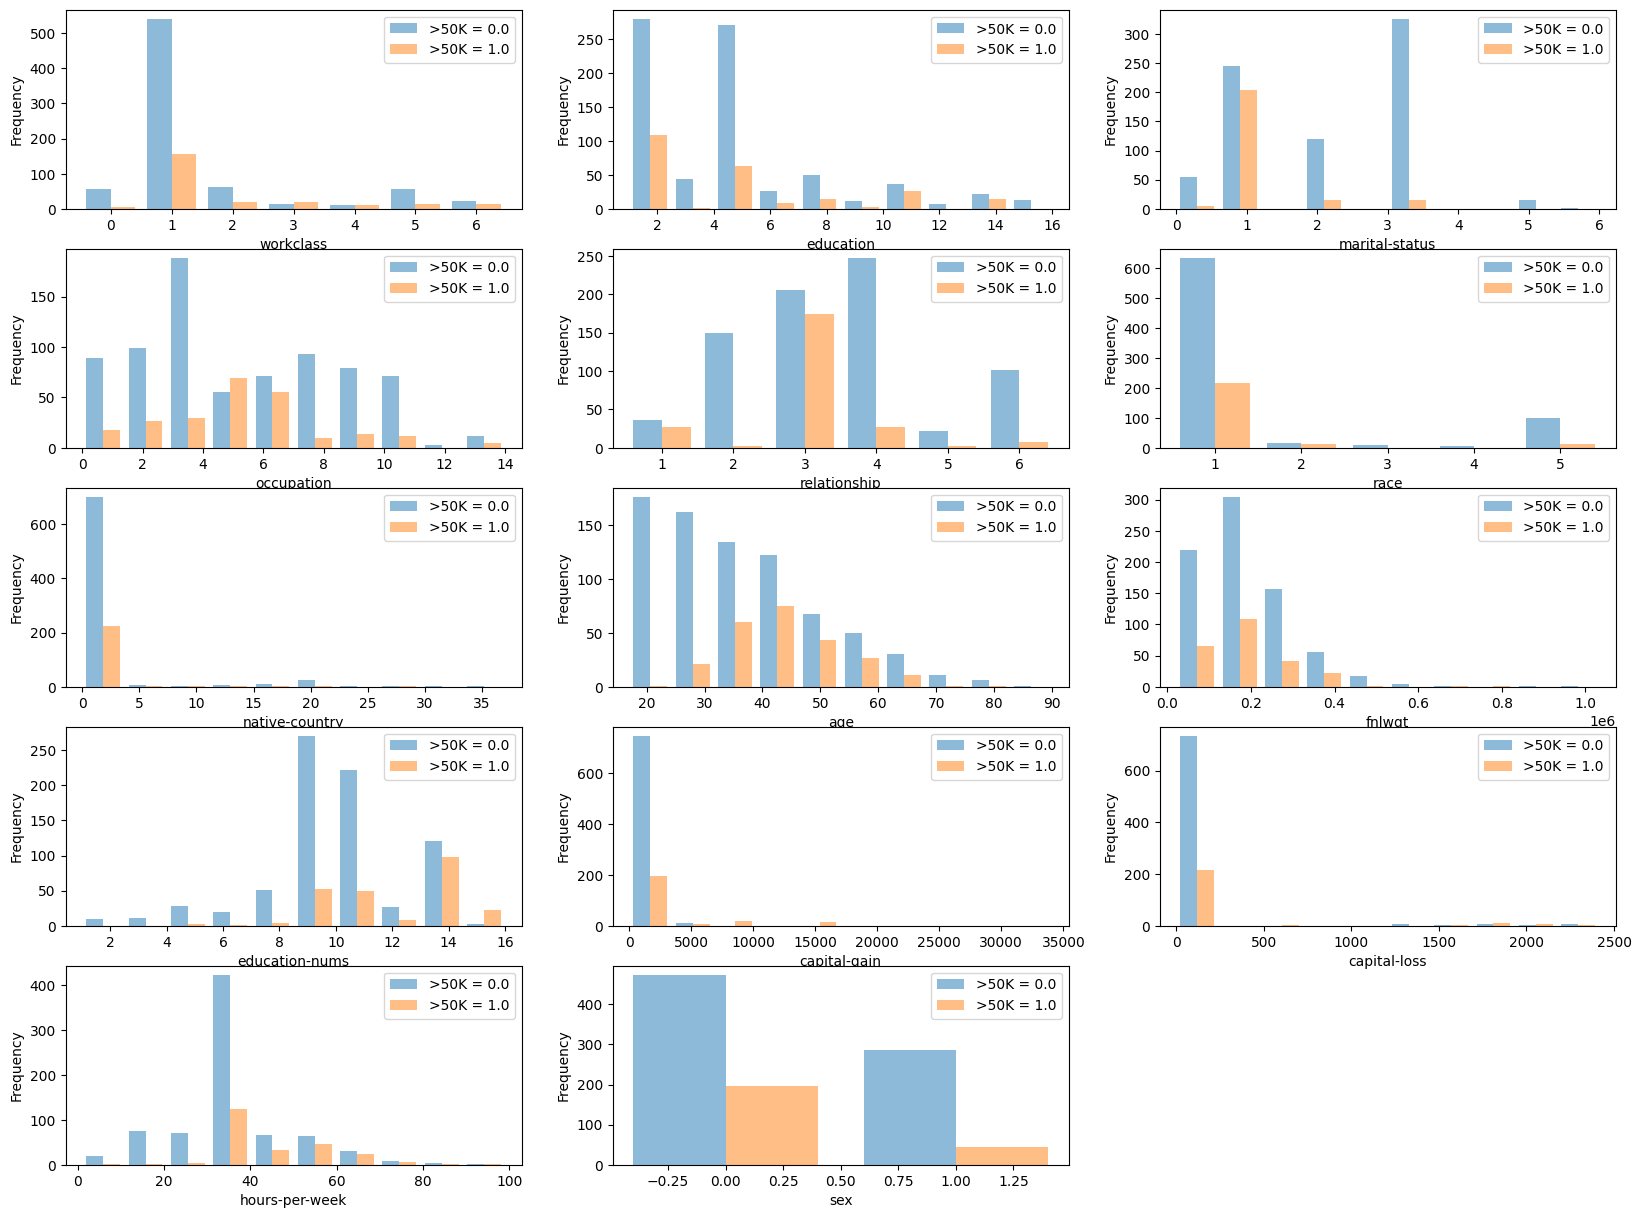

Classifying using Majority Vote...
	-- training error: 0.240
Classifying using Random...
	-- training error: 0.374
Classifying using Decision Tree...
	-- training error: 0.000
Classifying using k-Nearest Neighbors...
	-- training error: 0.153
	-- training error: 0.195
	-- training error: 0.213
Investigating various classifiers...


(0.24, 0.24, 0.7600000000000001)


(0.37477499999999997, 0.38199999999999995, 0.618)


(0.0, 0.20559999999999998, 0.7944)


(0.20167499999999997, 0.25915, 0.7408499999999999)
Finding the best k...


15 0.23699999999999996


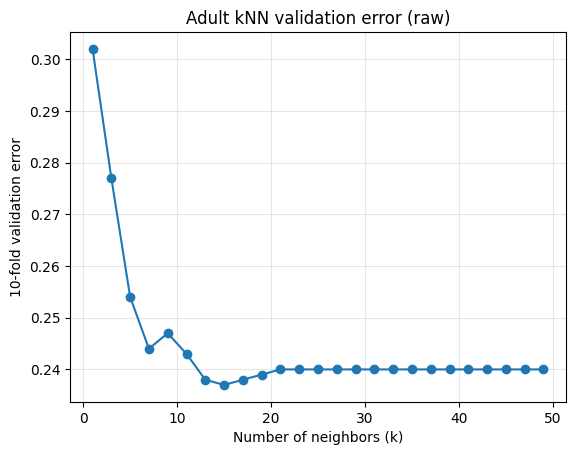

Investigating depths...


5 0.18200000000000002


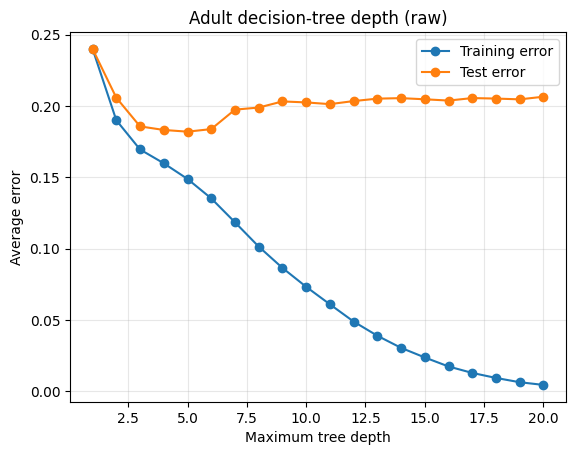

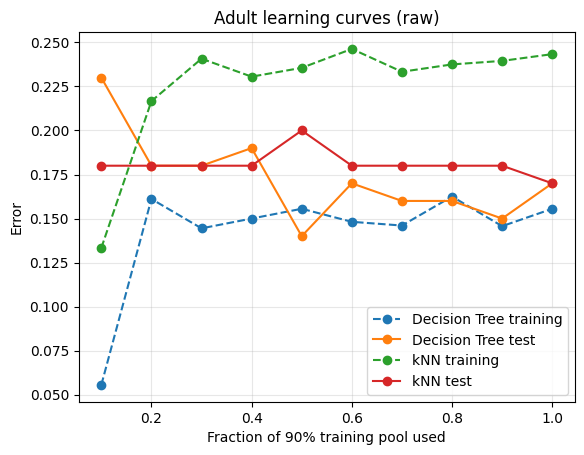

Classifying using Majority Vote...
	-- training error: 0.240
Classifying using Random...
	-- training error: 0.374
Classifying using Decision Tree...
	-- training error: 0.000
Classifying using k-Nearest Neighbors...
	-- training error: 0.114
	-- training error: 0.129
	-- training error: 0.152
Investigating various classifiers...


(0.24, 0.24, 0.7600000000000001)


(0.37477499999999997, 0.38199999999999995, 0.618)


(0.0, 0.20585, 0.7941499999999999)


(0.13244999999999998, 0.20769999999999997, 0.7923)
Finding the best k...


25 0.176


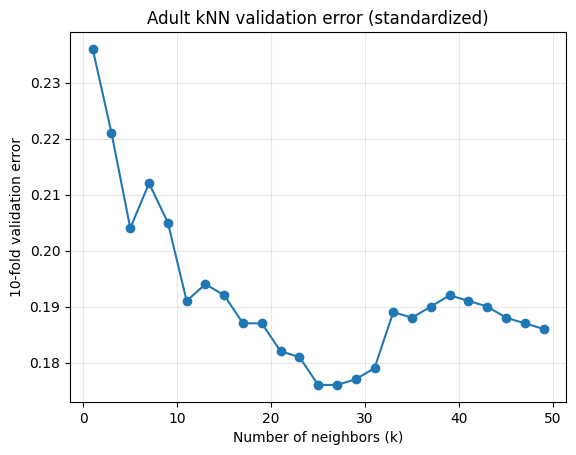

Investigating depths...


5 0.18220000000000003


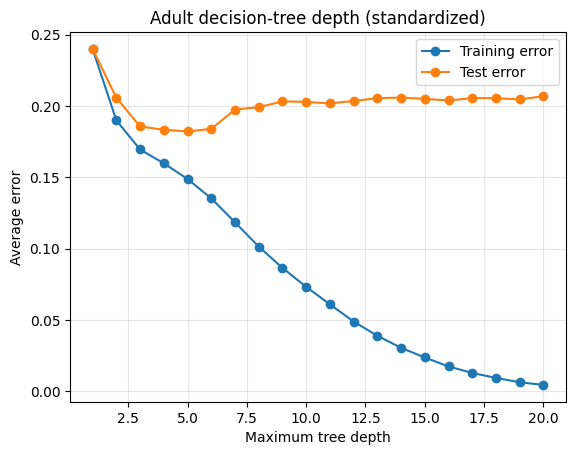

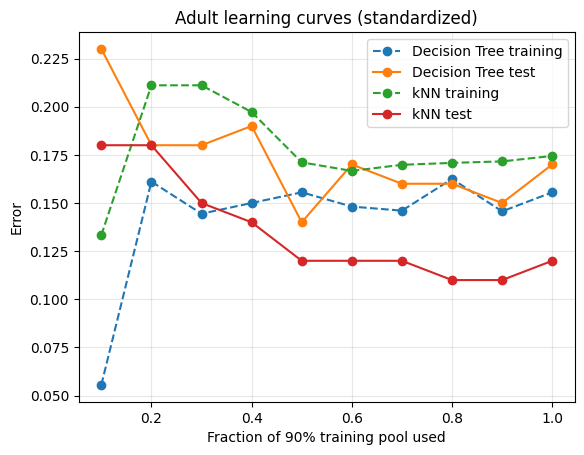

Done


In [11]:
######################################################################
# main
######################################################################

def main():
    # load adult_subsample dataset with correct file path
    ### ========== TODO : START ========== ###
    data_file = DATA_DIR / "adult_subsample.csv"
    ### ========== TODO : END ========== ###
    data = load_data(data_file, header=1, predict_col=-1)
    X, Xnames = data.X, data.Xnames
    y, yname = data.y, data.yname

    #========================================
    # part a: plot histograms of each feature
    print('Plotting...')
    plot_histograms(X, y, Xnames=Xnames, yname=yname)
    plt.show()

    def scaled_full_data(standardize):
        if not standardize:
            return X
        return StandardScaler().fit_transform(X)

    def knn_cv_errors(standardize):
        k_values = list(range(1, 50, 2))
        fold_splitter = StratifiedKFold(n_splits=10, shuffle=False)
        validation_errors = []
        for k in k_values:
            fold_errors = []
            for train_index, validation_index in fold_splitter.split(X, y):
                X_train, X_validation = X[train_index], X[validation_index]
                y_train, y_validation = y[train_index], y[validation_index]
                if standardize:
                    scaler = StandardScaler().fit(X_train)
                    X_train = scaler.transform(X_train)
                    X_validation = scaler.transform(X_validation)
                model = KNeighborsClassifier(n_neighbors=k)
                model.fit(X_train, y_train)
                fold_errors.append(1 - model.score(X_validation, y_validation))
            validation_errors.append(float(np.mean(fold_errors)))
        return k_values, validation_errors

    experiment_results = {}

    ### ========== TODO : START ========== ###
    # part i: First complete (b)-(h) with standardize=False, then repeat with True.
    # Keep X unchanged. Fit preprocessing only within each training partition.
    # For training error in (b)-(d), fitting on all X is appropriate.
    for standardize in (False, True):
        mode = "standardized" if standardize else "raw"
        X_full = scaled_full_data(standardize)
        mode_results = {}

        #========================================
        # train Majority Vote classifier on data
        print('Classifying using Majority Vote...')
        clf = MajorityVoteClassifier() # create MajorityVote classifier, which includes all model parameters
        clf.fit(X_full, y)             # fit training data using the classifier
        y_pred = clf.predict(X_full)   # take the classifier and run it on the training data
        train_error = 1 - metrics.accuracy_score(y, y_pred, normalize=True)
        mode_results["Majority Vote training error"] = train_error
        print('\t-- training error: %.3f' % train_error)

        ### ========== TODO : START ========== ###
        # part b: evaluate training error of Random classifier
        print('Classifying using Random...')
        clf = RandomClassifier ()
        clf.fit(X_full, y)
        y_pred = clf.predict(X_full)
        train_error = 1 - metrics.accuracy_score(y, y_pred, normalize=True)
        mode_results["Random training error"] = train_error
        print('\t-- training error: %.3f' % train_error)
        # print('\t-- training error: %.3f' % train_error)
        ### ========== TODO : END ========== ###

        ### ========== TODO : START ========== ###
        # part c: evaluate training error of Decision Tree classifier
        print('Classifying using Decision Tree...')
        # Use criterion='entropy', random_state=0.
        clf = DecisionTreeClassifier(criterion='entropy', random_state=0)
        clf.fit(X_full, y)
        y_pred = clf.predict(X_full)
        train_error = 1 - metrics.accuracy_score(y, y_pred, normalize=True)
        mode_results["Decision Tree training error"] = train_error
        print('\t-- training error: %.3f' % train_error)
        # print('\t-- training error: %.3f' % train_error)
        ### ========== TODO : END ========== ###

        ### ========== TODO : START ========== ###
        # part d: evaluate training error of k-Nearest Neighbors classifier
        # use k = 3, 5, 7 for n_neighbors
        print('Classifying using k-Nearest Neighbors...')
        # print the error for each k
        for k in (3, 5, 7):
            clf = KNeighborsClassifier(n_neighbors=k)
            clf.fit(X_full, y)
            train_error = 1 - clf.score(X_full, y)
            mode_results[f"kNN k={k} training error"] = train_error
            print('\t-- training error: %.3f' % train_error)
        ### ========== TODO : END ========== ###

        ### ========== TODO : START ========== ###
        # part e: use cross-validation to compute average training and test error of classifiers
        print('Investigating various classifiers...')
        # clf =
        evaluation_models = {
            "Majority Vote": MajorityVoteClassifier(),
            "Random": RandomClassifier(),
            "Decision Tree": DecisionTreeClassifier(criterion="entropy", random_state=0),
            "kNN (k=5)": KNeighborsClassifier(n_neighbors=5),
        }
        mode_results["part e"] = {}
        for name, clf in evaluation_models.items():
            summary = error(clf, X, y, ntrials=100, standardize=standardize)
            mode_results["part e"][name] = summary
            print(summary)
        # summary = error(clf, X, y, ntrials=100, standardize=standardize)
        # print(summary)
        ### ========== TODO : END ========== ###

        ### ========== TODO : START ========== ###
        # part f: use StratifiedKFold(10, shuffle=False), k=1,3,...,49.
        # Fit scaling separately inside each fold when standardize=True.
        # Choose the smallest k among tied minimum mean errors (tolerance 1e-12).
        print('Finding the best k...')
        k_values, k_errors = knn_cv_errors(standardize)
        minimum_k_error = min(k_errors)
        best_k = next(k for k, value in zip(k_values, k_errors)
                      if abs(value - minimum_k_error) <= 1e-12)
        mode_results["best k"] = best_k
        mode_results["k validation errors"] = k_errors
        print(best_k, minimum_k_error)
        plt.figure()
        plt.plot(k_values, k_errors, marker="o")
        plt.xlabel("Number of neighbors (k)")
        plt.ylabel("10-fold validation error")
        plt.title(f"Adult kNN validation error ({mode})")
        plt.grid(alpha=0.3)
        plt.savefig(DATA_DIR / f"adult_knn_cv_{mode}.pdf", bbox_inches="tight")
        plt.show()
        ### ========== TODO : END ========== ###

        ### ========== TODO : START ========== ###
        # part g: entropy trees with random_state=0, depths 1,...,20.
        # Use error(..., standardize=standardize); smallest depth wins a tie.
        print('Investigating depths...')
        depths = list(range(1, 21))
        depth_train_errors, depth_test_errors = [], []
        for depth in depths:
            summary = error(
                DecisionTreeClassifier(criterion="entropy", max_depth=depth,
                                       random_state=0),
                X, y, ntrials=100, standardize=standardize
            )
            depth_train_errors.append(summary[0])
            depth_test_errors.append(summary[1])
        minimum_depth_error = min(depth_test_errors)
        best_depth = next(depth for depth, value in zip(depths, depth_test_errors)
                          if abs(value - minimum_depth_error) <= 1e-12)
        mode_results["best depth"] = best_depth
        mode_results["depth train errors"] = depth_train_errors
        mode_results["depth test errors"] = depth_test_errors
        print(best_depth, minimum_depth_error)
        plt.figure()
        plt.plot(depths, depth_train_errors, marker="o", label="Training error")
        plt.plot(depths, depth_test_errors, marker="o", label="Test error")
        plt.xlabel("Maximum tree depth")
        plt.ylabel("Average error")
        plt.title(f"Adult decision-tree depth ({mode})")
        plt.legend()
        plt.grid(alpha=0.3)
        plt.savefig(DATA_DIR / f"adult_tree_depth_{mode}.pdf", bbox_inches="tight")
        plt.show()
        ### ========== TODO : END ========== ###

        ### ========== TODO : START ========== ###
        # part h: investigate decision tree and k-Nearest Neighbors classifier with various training set sizes
        # Reuse best k and depth from (f) and (g), matching the original assignment.
        # Use train_test_split(..., test_size=0.1, random_state=0), without stratify.
        # Use np.random.RandomState(0).permutation on the 90% training indices;
        # take nested prefixes of floor(fraction * n_train), fraction=.1,.2,...,1.
        # Fit scaling on each prefix. These learning curves are illustrative,
        # because the parameter selection above used the full dataset.
        all_indices = np.arange(len(y))
        train_pool, test_indices = train_test_split(
            all_indices, test_size=0.1, random_state=0
        )
        train_pool = np.random.RandomState(0).permutation(train_pool)
        fractions = np.arange(0.1, 1.01, 0.1)
        learning_results = {}
        learning_models = {
            "Decision Tree": DecisionTreeClassifier(
                criterion="entropy", max_depth=best_depth, random_state=0
            ),
            "kNN": KNeighborsClassifier(n_neighbors=best_k),
        }
        plt.figure()
        for name, base_model in learning_models.items():
            train_curve, test_curve = [], []
            for fraction in fractions:
                sample_size = int(np.floor(fraction * len(train_pool)))
                subset = train_pool[:sample_size]
                X_train, y_train = X[subset], y[subset]
                X_test, y_test = X[test_indices], y[test_indices]
                if standardize:
                    scaler = StandardScaler().fit(X_train)
                    X_train = scaler.transform(X_train)
                    X_test = scaler.transform(X_test)
                model = deepcopy(base_model)
                model.fit(X_train, y_train)
                train_curve.append(1 - model.score(X_train, y_train))
                test_curve.append(1 - model.score(X_test, y_test))
            learning_results[name] = {
                "training error": train_curve, "test error": test_curve
            }
            plt.plot(fractions, train_curve, marker="o", linestyle="--",
                     label=f"{name} training")
            plt.plot(fractions, test_curve, marker="o", label=f"{name} test")
        mode_results["learning curves"] = learning_results
        plt.xlabel("Fraction of 90% training pool used")
        plt.ylabel("Error")
        plt.title(f"Adult learning curves ({mode})")
        plt.legend()
        plt.grid(alpha=0.3)
        plt.savefig(DATA_DIR / f"adult_learning_curves_{mode}.pdf", bbox_inches="tight")
        plt.show()
        ### ========== TODO : END ========== ###

        experiment_results[mode] = mode_results
    ### ========== TODO : END ========== ###

    print('Done')
    return experiment_results


if __name__ == "__main__":
    adult_experiment_results = main()


## Extension to multiclass classification

Adapt your Adult implementation to train and evaluate kNN and a decision tree on `dry_bean.csv`: **1,000 examples, 16 features, seven classes**. The final `Class` column is the target: BARBUNYA=0, BOMBAY=1, CALI=2, DERMASON=3, HOROZ=4, SEKER=5, SIRA=6. Following the Adult experiment, use cross-validation to select k from the odd numbers between 1 and 50 and the decision-tree depth limit from 1 through 20. Plot the cross-validation error against each hyperparameter and justify your selections. Report the test error and test micro-averaged F1 score for both selected classifiers, as requested in the handout. Place `dry_bean.csv` in `DATA_DIR`, complete the TODO below, and run the cell. Include the extension code, saved outputs and plots in your PDF submission.


C:\Users\kier0\AppData\Local\Programs\Python\Python310\lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\kier0\AppData\Local\Programs\Python\Python310\lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
  File "C:\Users\kier0\AppData\Local\Programs\Python\Python310\lib\subprocess.py", line 501, in run
    with Popen(*popenargs, **kwargs) as process:
  File "C:\Users\kier0\AppData\Local\Programs\Python\Python310\lib\subprocess.py", line 966, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\kier0\AppData\Local\Programs\Python\Python310\lib\subp

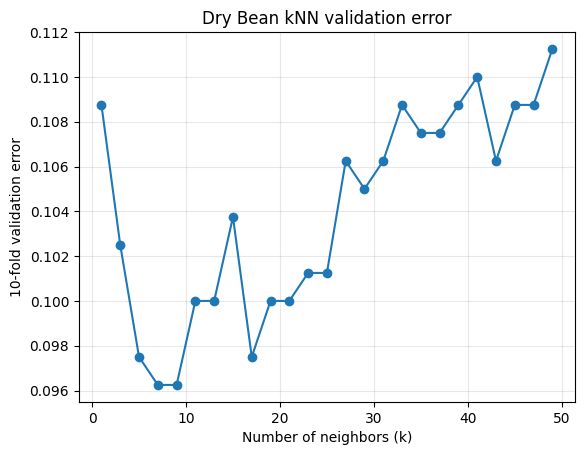

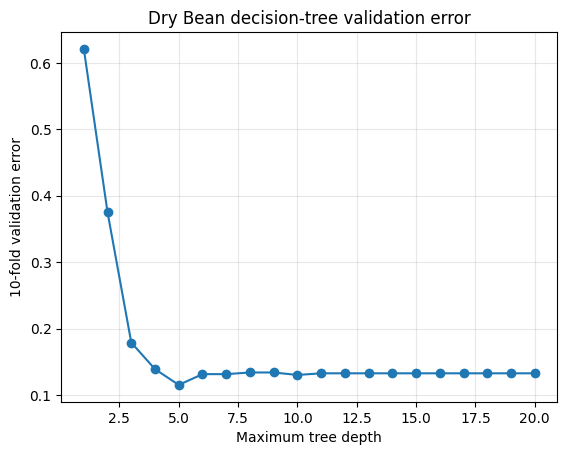

Best Dry Bean k: 7 (CV error 0.0962)
Best Dry Bean tree depth: 5 (CV error 0.1150)
kNN test error=0.0850, micro-F1=0.9150
Tree test error=0.1250, micro-F1=0.8750


In [12]:
def run_extension(data_path):
    ### ========== TODO : START ========== ###
    # Load data_path: 16 input columns followed by the Class target (0–6).
    # Adapt your Adult implementation for seven classes.
    # Search odd k values from 1 to 49 and tree depth limits from 1 to 20 using CV.
    # Plot CV errors and justify the selected parameters in your writeup.
    # Report test error and micro-averaged F1 for both selected classifiers.
    bean_data = load_data(data_path, header=1, predict_col=-1)
    X_bean, y_bean = bean_data.X, bean_data.y
    X_train, X_test, y_train, y_test = train_test_split(
        X_bean, y_bean, test_size=0.2, random_state=0, stratify=y_bean
    )
    cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=0)

    def mean_cv_error(model_factory, standardize):
        fold_errors = []
        for fit_index, validation_index in cv.split(X_train, y_train):
            X_fit, X_validation = X_train[fit_index], X_train[validation_index]
            y_fit, y_validation = y_train[fit_index], y_train[validation_index]
            if standardize:
                scaler = StandardScaler().fit(X_fit)
                X_fit = scaler.transform(X_fit)
                X_validation = scaler.transform(X_validation)
            model = model_factory()
            model.fit(X_fit, y_fit)
            fold_errors.append(1 - model.score(X_validation, y_validation))
        return float(np.mean(fold_errors))

    k_values = list(range(1, 50, 2))
    k_errors = [
        mean_cv_error(lambda k=k: KNeighborsClassifier(n_neighbors=k), True)
        for k in k_values
    ]
    best_k_error = min(k_errors)
    best_k = next(k for k, value in zip(k_values, k_errors)
                  if abs(value - best_k_error) <= 1e-12)

    depths = list(range(1, 21))
    depth_errors = [
        mean_cv_error(
            lambda depth=depth: DecisionTreeClassifier(
                criterion="entropy", max_depth=depth, random_state=0
            ),
            False,
        )
        for depth in depths
    ]
    best_depth_error = min(depth_errors)
    best_depth = next(depth for depth, value in zip(depths, depth_errors)
                      if abs(value - best_depth_error) <= 1e-12)

    plt.figure()
    plt.plot(k_values, k_errors, marker="o")
    plt.xlabel("Number of neighbors (k)")
    plt.ylabel("10-fold validation error")
    plt.title("Dry Bean kNN validation error")
    plt.grid(alpha=0.3)
    plt.savefig(DATA_DIR / "dry_bean_knn_cv.pdf", bbox_inches="tight")
    plt.show()

    plt.figure()
    plt.plot(depths, depth_errors, marker="o")
    plt.xlabel("Maximum tree depth")
    plt.ylabel("10-fold validation error")
    plt.title("Dry Bean decision-tree validation error")
    plt.grid(alpha=0.3)
    plt.savefig(DATA_DIR / "dry_bean_tree_depth_cv.pdf", bbox_inches="tight")
    plt.show()

    scaler = StandardScaler().fit(X_train)
    knn = KNeighborsClassifier(n_neighbors=best_k)
    knn.fit(scaler.transform(X_train), y_train)
    knn_prediction = knn.predict(scaler.transform(X_test))

    tree = DecisionTreeClassifier(
        criterion="entropy", max_depth=best_depth, random_state=0
    )
    tree.fit(X_train, y_train)
    tree_prediction = tree.predict(X_test)

    results = {
        "best k": best_k,
        "best depth": best_depth,
        "kNN test error": 1 - metrics.accuracy_score(y_test, knn_prediction),
        "kNN micro-F1": metrics.f1_score(y_test, knn_prediction, average="micro"),
        "tree test error": 1 - metrics.accuracy_score(y_test, tree_prediction),
        "tree micro-F1": metrics.f1_score(y_test, tree_prediction, average="micro"),
        "k validation errors": k_errors,
        "depth validation errors": depth_errors,
    }
    print(f"Best Dry Bean k: {best_k} (CV error {best_k_error:.4f})")
    print(f"Best Dry Bean tree depth: {best_depth} (CV error {best_depth_error:.4f})")
    print(f"kNN test error={results['kNN test error']:.4f}, "
          f"micro-F1={results['kNN micro-F1']:.4f}")
    print(f"Tree test error={results['tree test error']:.4f}, "
          f"micro-F1={results['tree micro-F1']:.4f}")

    return results
    ### ========== TODO : END ========== ###

bean_extension_results = run_extension(DATA_DIR / 'dry_bean.csv')
